# Projet — différences entre la NAV et le prix de marché des ETF

## Problématique

Deux actifs peuvent représenter le même investissement — l'ETF et le portefeuille sous-jacent constitué par le fond, représenté par sa valeur nette des actifs (NAV) — tout en affichant des prix différents. L'objectif est de mesurer ces écarts, de voir si ils sont liés au régime de marché (volattilité et liquidité) et d'observer s'ils se corrigent rapidement.

L'étude se concentre sur 4 ETF : SPY, SPEM, SPIB et SPHY répliquant respectivement  le S&P500, les marchés actions émergents, un panier d'obligations Investment Grade (à faible risque de défaut), et un panier d'obligations High Yield (à forte probabilité de défaut).
On comparera la NAV quotidienne aux prix de ces 4 ETF.

Les étapes sont : (1) nettoyer les données de NAV et de prix de clôture, (2) calculer la prime/décote, (3) comparer les écarts selon la volatilité et la liquidité, puis (4) mesurer la correction le jour suivant.

## 1. Importation et nettoyage des données de NAV

La première cellule télécharge les historiques de NAV dans un dataframe, et les nettoie en retirant toutes les dates sans NAV. On préfère cela à de l'interpolation ou à une moyenne car on créerait alors artificiellement des écarts importants entre NAV et ETFs (les écarts étant usuellement très faibles).

La NAV (*Net Asset Value*) représente la valeur par part du portefeuille détenu par l'ETF et peut être résumée par la relation :

$$\mathrm{NAV}_t = \frac{\text{valeur des actifs du portefeuille à }t}{\text{nombre de parts de l'ETF à }t}$$

Pour les valeurs manquantes, on fait également le choix de ne pas interpoler ou utiliser une quelconque autre méthode de remplacement, en raison des écarts artificiellement grands que cela créerait entre prix d'ETF et NAV, ce qui perturberait de beaucoup l'analyse.



In [9]:
from pathlib import Path
import sys

RACINE = Path.cwd()
if not (RACINE / "fonctions").is_dir():
    RACINE = RACINE.parent
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

from fonctions.a_donnees import charger_nav, charger_prix
from fonctions.b_analyses import construire_donnees, statistiques_ecarts
from fonctions.c_graphiques import tracer_primes_decotes

In [10]:
nav = charger_nav()
for ticker, historique in nav.items():
    print(ticker.upper(), len(historique), historique["Date"].min(), historique["Date"].max())
    display(historique.head())

SPY 5785 2003-12-01 00:00:00 2026-11-23 00:00:00


,Date,NAV,Shares Outstanding,Total Net Assets
0,2003-12-01,107.61,-,-
1,2003-12-02,107.26,-,-
2,2003-12-03,107.10,-,-
3,2003-12-04,107.61,-,-
4,2003-12-05,106.79,-,-


SPEM 4955 2007-03-21 00:00:00 2026-11-23 00:00:00


,Date,NAV,Shares Outstanding,Total Net Assets
0,2007-03-21,56.296426,300000.0,16888927.84
1,2007-03-22,57.081256,300000.0,17124376.88
2,2007-03-23,57.316085,300000.0,17194825.49
3,2007-03-26,57.296408,300000.0,17188922.39
4,2007-03-27,57.138245,300000.0,17141473.43


SPIB 4478 2009-02-10 00:00:00 2026-11-23 00:00:00


,Date,NAV,Shares Outstanding,Total Net Assets
0,2009-02-10,30.000000,200000.0,6000000.00
1,2009-02-11,29.877218,200000.0,5975443.53
2,2009-02-12,29.893633,200000.0,5978726.63
3,2009-02-13,29.706208,200000.0,5941241.59
4,2009-02-17,29.843575,200000.0,5968715.06


SPHY 3632 2012-06-19 00:00:00 2026-11-23 00:00:00


,Date,NAV,Shares Outstanding,Total Net Assets
0,2012-06-19,25.070512,400000.0,10028204.90
1,2012-06-20,25.111529,400000.0,10044611.66
2,2012-06-21,25.161863,400000.0,10064745.34
3,2012-06-22,25.140285,400000.0,10056114.06
4,2012-06-25,25.165986,400000.0,10066394.29


## 2. Importation des prix de marché et des volumes

On récupère les prix de clôture et les volumes des quatre ETF via Yahoo Finance. Le prix de marché est celui auquel l'ETF s'échange en bourse. Les volumes nous serveront de proxy pour calculer la liquidité d'un ETF. 
Comme précédemment, on nettoie le dataframe et on en retire les valeurs manquantes.

Le prix utilisé est le cours de clôture :

$$P_t^{\mathrm{marché}} = \mathrm{Close}_t$$


In [11]:
prix = charger_prix()
for ticker, historique in prix.items():
    print(ticker, len(historique), historique["Date"].min(), historique["Date"].max())
    display(historique.head())

SPY 3601 2012-06-19 00:00:00 2026-10-14 00:00:00


Price,Date,Close,Volume
0,2012-06-19,135.699997,137382600
1,2012-06-20,135.479996,206451800
2,2012-06-21,132.440002,205272200
3,2012-06-22,133.460007,130029200
4,2012-06-25,131.320007,146375700


SPEM 3601 2012-06-19 00:00:00 2026-10-14 00:00:00


Price,Date,Close,Volume
0,2012-06-19,30.070000,4800
1,2012-06-20,30.004999,54200
2,2012-06-21,28.959999,19800
3,2012-06-22,29.129999,23200
4,2012-06-25,28.610001,8200


SPIB 3601 2012-06-19 00:00:00 2026-10-14 00:00:00


Price,Date,Close,Volume
0,2012-06-19,33.980000,23800
1,2012-06-20,33.980000,34900
2,2012-06-21,34.090000,271300
3,2012-06-22,34.000000,113600
4,2012-06-25,34.060001,14400


SPHY 3601 2012-06-19 00:00:00 2026-10-14 00:00:00


Price,Date,Close,Volume
0,2012-06-19,25.400000,4000
1,2012-06-20,25.559999,2100
2,2012-06-21,25.459999,1400
3,2012-06-22,25.500000,800
4,2012-06-25,25.500000,1600


## 3. Fusion des dataframes NAV et ETF et calcul des primes et décotes.

La fusion ne conserve que les dates communes entre NAV et prix de clôture. Pour chaque date, l'écart relatif est calculé ainsi :

$$\mathrm{Prime/Décote}_t = \frac{P_t^{\mathrm{marché}} - \mathrm{NAV}_t}{\mathrm{NAV}_t} \times 100$$

Une valeur positive correspond à une prime et une valeur négative à une décote. On calcule aussi l'écart absolu :

$$\mathrm{Écart\ absolu}_t = \left|\mathrm{Prime/Décote}_t\right|$$

L'ajustement du split 2-pour-1 de SPEM avant le 16 octobre 2017 évite de confondre une rupture technique avec un véritable écart économique.

On analyse aussi à quelle fréquence les écarts NAV-ETF dépassent certains seuils prédéterminés (0.25%, 0.5% et 1%).


> Convention : une prime/décote positive signifie que le prix de marché est supérieur à la NAV ; une valeur négative correspond à une décote.

3601
3601
3601
3601


,ETF,Date,Close,NAV,Volume,Prime_decote_pct,Prime_decote_moyenne_30j
0,SPEM,2012-06-19,30.070000,29.831433,4800,0.799714,NaN
1,SPEM,2012-06-20,30.004999,29.905950,54200,0.331201,NaN
2,SPEM,2012-06-21,28.959999,29.324434,19800,-1.242770,NaN
3,SPEM,2012-06-22,29.129999,28.989788,23200,0.483655,NaN
4,SPEM,2012-06-25,28.610001,28.592290,8200,0.061942,0.086748


,ETF,Classe,Type,Nombre_observations,Prime_decote_moyenne_pct,Prime_decote_mediane_pct,Ecart_absolu_moyen_pct,Ecart_absolu_max_pct,Jours_au_dessus_0.25pct,Jours_au_dessus_0.5pct,Jours_au_dessus_1.0pct
0,SPEM,Actions,Actions émergentes,3601,0.0759,0.1046,0.4514,4.3401,63.6768,35.0736,8.0533
1,SPHY,Obligations,Obligations high yield,3601,0.1632,0.1483,0.3336,4.4806,45.4041,19.7445,6.1927
2,SPIB,Obligations,Obligations investment grade,3601,0.0913,0.0570,0.1315,6.1028,15.3291,3.8600,0.3055
3,SPY,Actions,Actions américaines,3601,0.0020,0.0036,0.0242,0.9004,0.3055,0.0555,0.0000


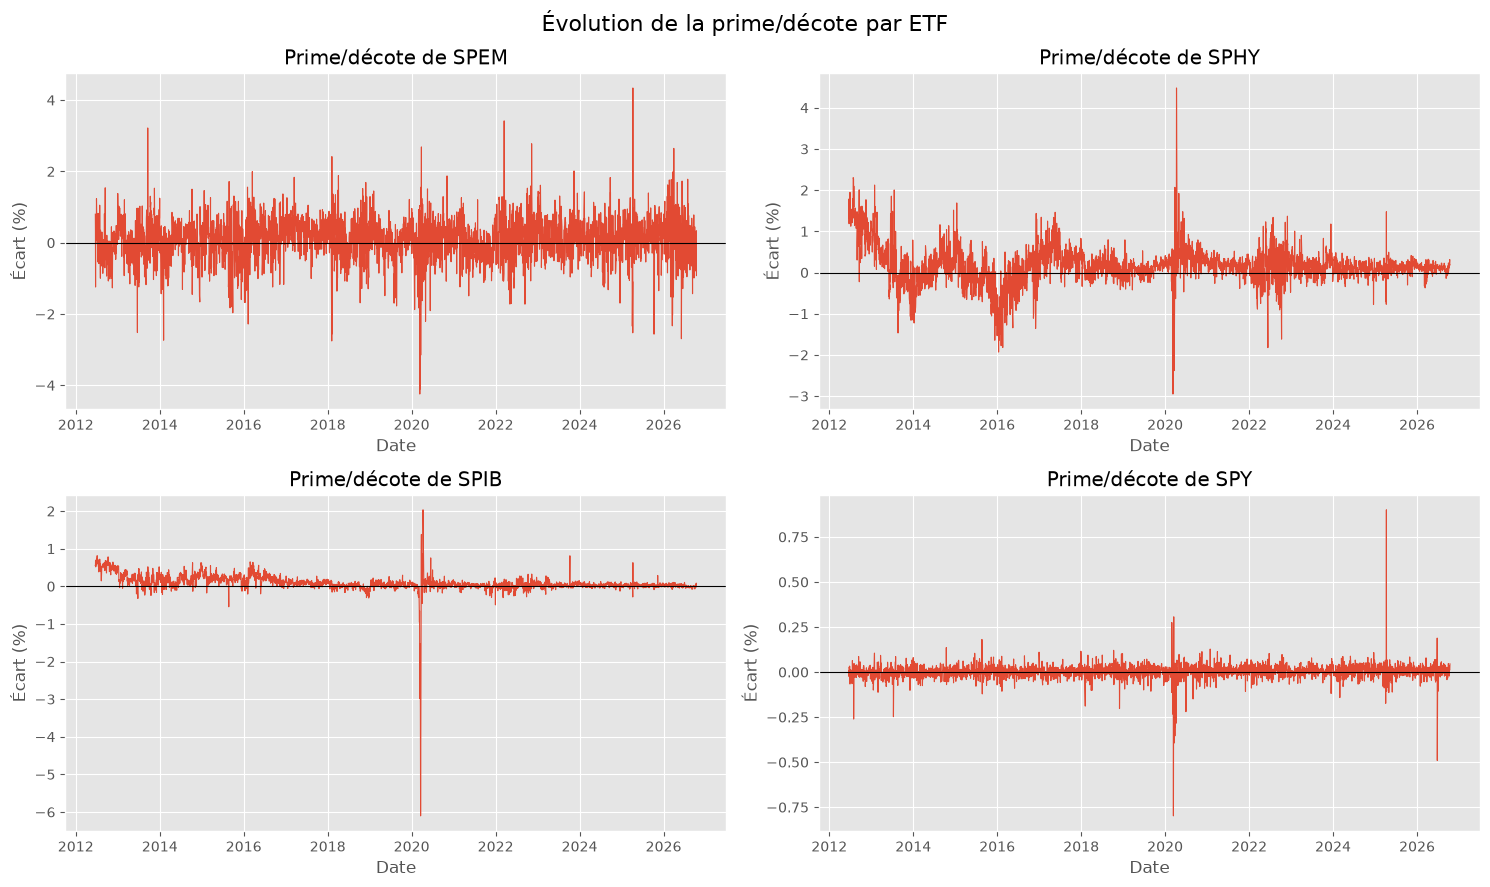

In [12]:
donnees = construire_donnees(nav, prix)
statistiques = statistiques_ecarts(donnees)
for ticker, historique in donnees.groupby("ETF", sort=False):
    print(len(historique))

display(donnees[["ETF", "Date", "Close", "NAV", "Volume", "Prime_decote_pct", "Prime_decote_moyenne_30j"]].head())
display(statistiques.round(4))

fig = tracer_primes_decotes(donnees)
display(fig)
import matplotlib.pyplot as plt
plt.close(fig)

### Résultats de la fusion des données

La fusion produit **3 601 dates communes par ETF**. L'écart absolu moyen est de **0,0242 % pour SPY**, **0,1315 % pour SPIB**, **0,3336 % pour SPHY** et **0,4514 % pour SPEM**.

La proportion de jours où l'écart dépasse 0,25 % est respectivement de **0,31 %**, **15,33 %**, **45,40 %** et **63,68 %** pour SPY, SPIB, SPHY et SPEM.

SPY et SPIB suivent très étroitement sa NAV, alors que SPEM et SPHY présentent les écarts les plus fréquents entre NAV et valeur de l'ETF.

On peut attribuer cette différence au fait que les sous-jacents de SPEM et SPHY sont généralement moins liquides, ce qui rend leur achat et vente par le détenteur du fond pour recalibrer sa réplication de l'ETF plus difficile en cas de stress de marché.

Les pics observés en 2020, notamment en mars, correspondent au choc de la pandémie de Covid-19 : la forte volatilité, les ventes massives et la baisse de la liquidité ont temporairement amplifié les primes et décotes, surtout pour SPEM et SPHY.